**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 8**
Regresión Lineal

---

Equipo 29
- José Antonio Guizar Pascacio, A01174201
- Isaac Antonio Gutiérrez Díaz, A01841319
- Ramón Gutiérrez Lara, A01840916
- Aarón Hernández Jiménez, A01642529

En esta actividad trabajarás con el archivo `diamonds_dataset.csv`, basado en un conjunto de datos sobre características de diamantes, disponible en el paquete ggplot2 de R y en repositorios públicos de análisis de datos.

Los datos fueron recopilados para analizar el precio de los diamantes en función de sus propiedades físicas y cualidades de corte, color y claridad. Los indicadores incluidos son:

* `carat`: Peso del diamante en quilates
* `cut`: Calidad del corte del diamante (Fair, Good, Very Good, Premium, Ideal)
* `color`: Color del diamante, de D (mejor) a J (peor)
* `clarity`: Claridad del diamante (I1, SI2, SI1, VS2, VS1, VVS2, VVS1, IF)
* `depth`: Profundidad total del diamante como porcentaje: z / mean(x, y)
* `table`: Ancho de la tabla del diamante como porcentaje de x
* `x`: Longitud en mm
* `y`: Ancho en mm
* `z`: Profundidad en mm
* `price`: Precio del diamante en dólares estadounidenses. Es la variable de salida o *target*

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [1]:
# Importar las bibliotecas necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, RobustScaler
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import root_mean_squared_error, r2_score

1. Descarga el archivo: `diamonds_dataset.csv` y guarda, en un dataframe (`diamonds_df`), todos sus registros.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?
* Determina la cantidad de valores únicos por columna.
* Verifica si alguna columna contiene valores faltantes.
* Si existen registros duplicados, elimínalos del dataframe y reinicia el índice para que se mantenga consecutivo.

In [2]:
diamonds_df = pd.read_csv('diamonds_dataset.csv')
diamonds_df.info()
print(diamonds_df.nunique())
print(diamonds_df.isnull().sum())
print('Duplicados:', diamonds_df.duplicated().sum())
diamonds_df = diamonds_df.drop_duplicates().reset_index(drop=True)
print('Registros después de quitar duplicados:', diamonds_df.shape[0])

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53916 entries, 0 to 53915
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    53916 non-null  float64
 1   cut      53916 non-null  object 
 2   color    53916 non-null  object 
 3   clarity  53916 non-null  object 
 4   depth    53916 non-null  float64
 5   table    53916 non-null  float64
 6   x        53916 non-null  float64
 7   y        53916 non-null  float64
 8   z        53916 non-null  float64
 9   price    53916 non-null  int64  
dtypes: float64(6), int64(1), object(3)
memory usage: 4.1+ MB
carat        271
cut            5
color          7
clarity        8
depth        184
table        127
x            550
y            549
z            371
price      11595
dtype: int64
carat      0
cut        0
color      0
clarity    0
depth      0
table      0
x          0
y          0
z          0
price      0
dtype: int64
Duplicados: 145
Registros después de quitar dup

Respuesta 1

El archivo tiene 53,916 diamantes y 10 columnas. Siete son números (carat, depth, table, x, y, z y price) y tres son texto (cut, color y clarity).

Las columnas de texto tienen pocas opciones: 5 tipos de corte, 7 colores y 8 niveles de claridad. No falta ningún dato. Lo único raro fueron 145 registros repetidos; se quitaron y quedaron 53,771 diamantes.

2. Obtén las estadísticas descriptivas, separando las variables numéricas y las categóricas. De estas últimas incluye las tablas de frecuencia.
* Para las variables numéricas genera histogramas y boxplots para explorar la distribución y la dispersión.
* Para las variables categóricas utiliza diagramas de barras para visualizar la frecuencia de cada categoría.

,count,mean,std,min,25%,50%,75%,max
carat,53771.0,0.797323,0.472474,0.20,0.40,0.70,1.04,4.50
depth,53771.0,61.748160,1.429519,43.00,61.00,61.80,62.50,79.00
table,53771.0,57.457635,2.233192,43.00,56.00,57.00,59.00,95.00
x,53771.0,5.731280,1.118102,3.73,4.71,5.70,6.54,10.23
y,53771.0,5.734618,1.138982,3.68,4.72,5.71,6.54,58.90
z,53771.0,3.539774,0.701677,1.07,2.91,3.53,4.03,31.80
price,53771.0,3930.320545,3984.687429,326.00,951.00,2401.00,5323.50,18823.00


,count,unique,top,freq
cut,53771,5,Ideal,21485
color,53771,7,G,11254
clarity,53771,8,SI1,13030


,count
cut,
Ideal,21485
Premium,13737
Very Good,12065
Good,4888
Fair,1596


,count
color,
G,11254
E,9776
F,9517
H,8266
D,6753
I,5404
J,2801


,count
clarity,
SI1,13030
VS2,12225
SI2,9140
VS1,8155
VVS2,5056
VVS1,3646
IF,1784
I1,735


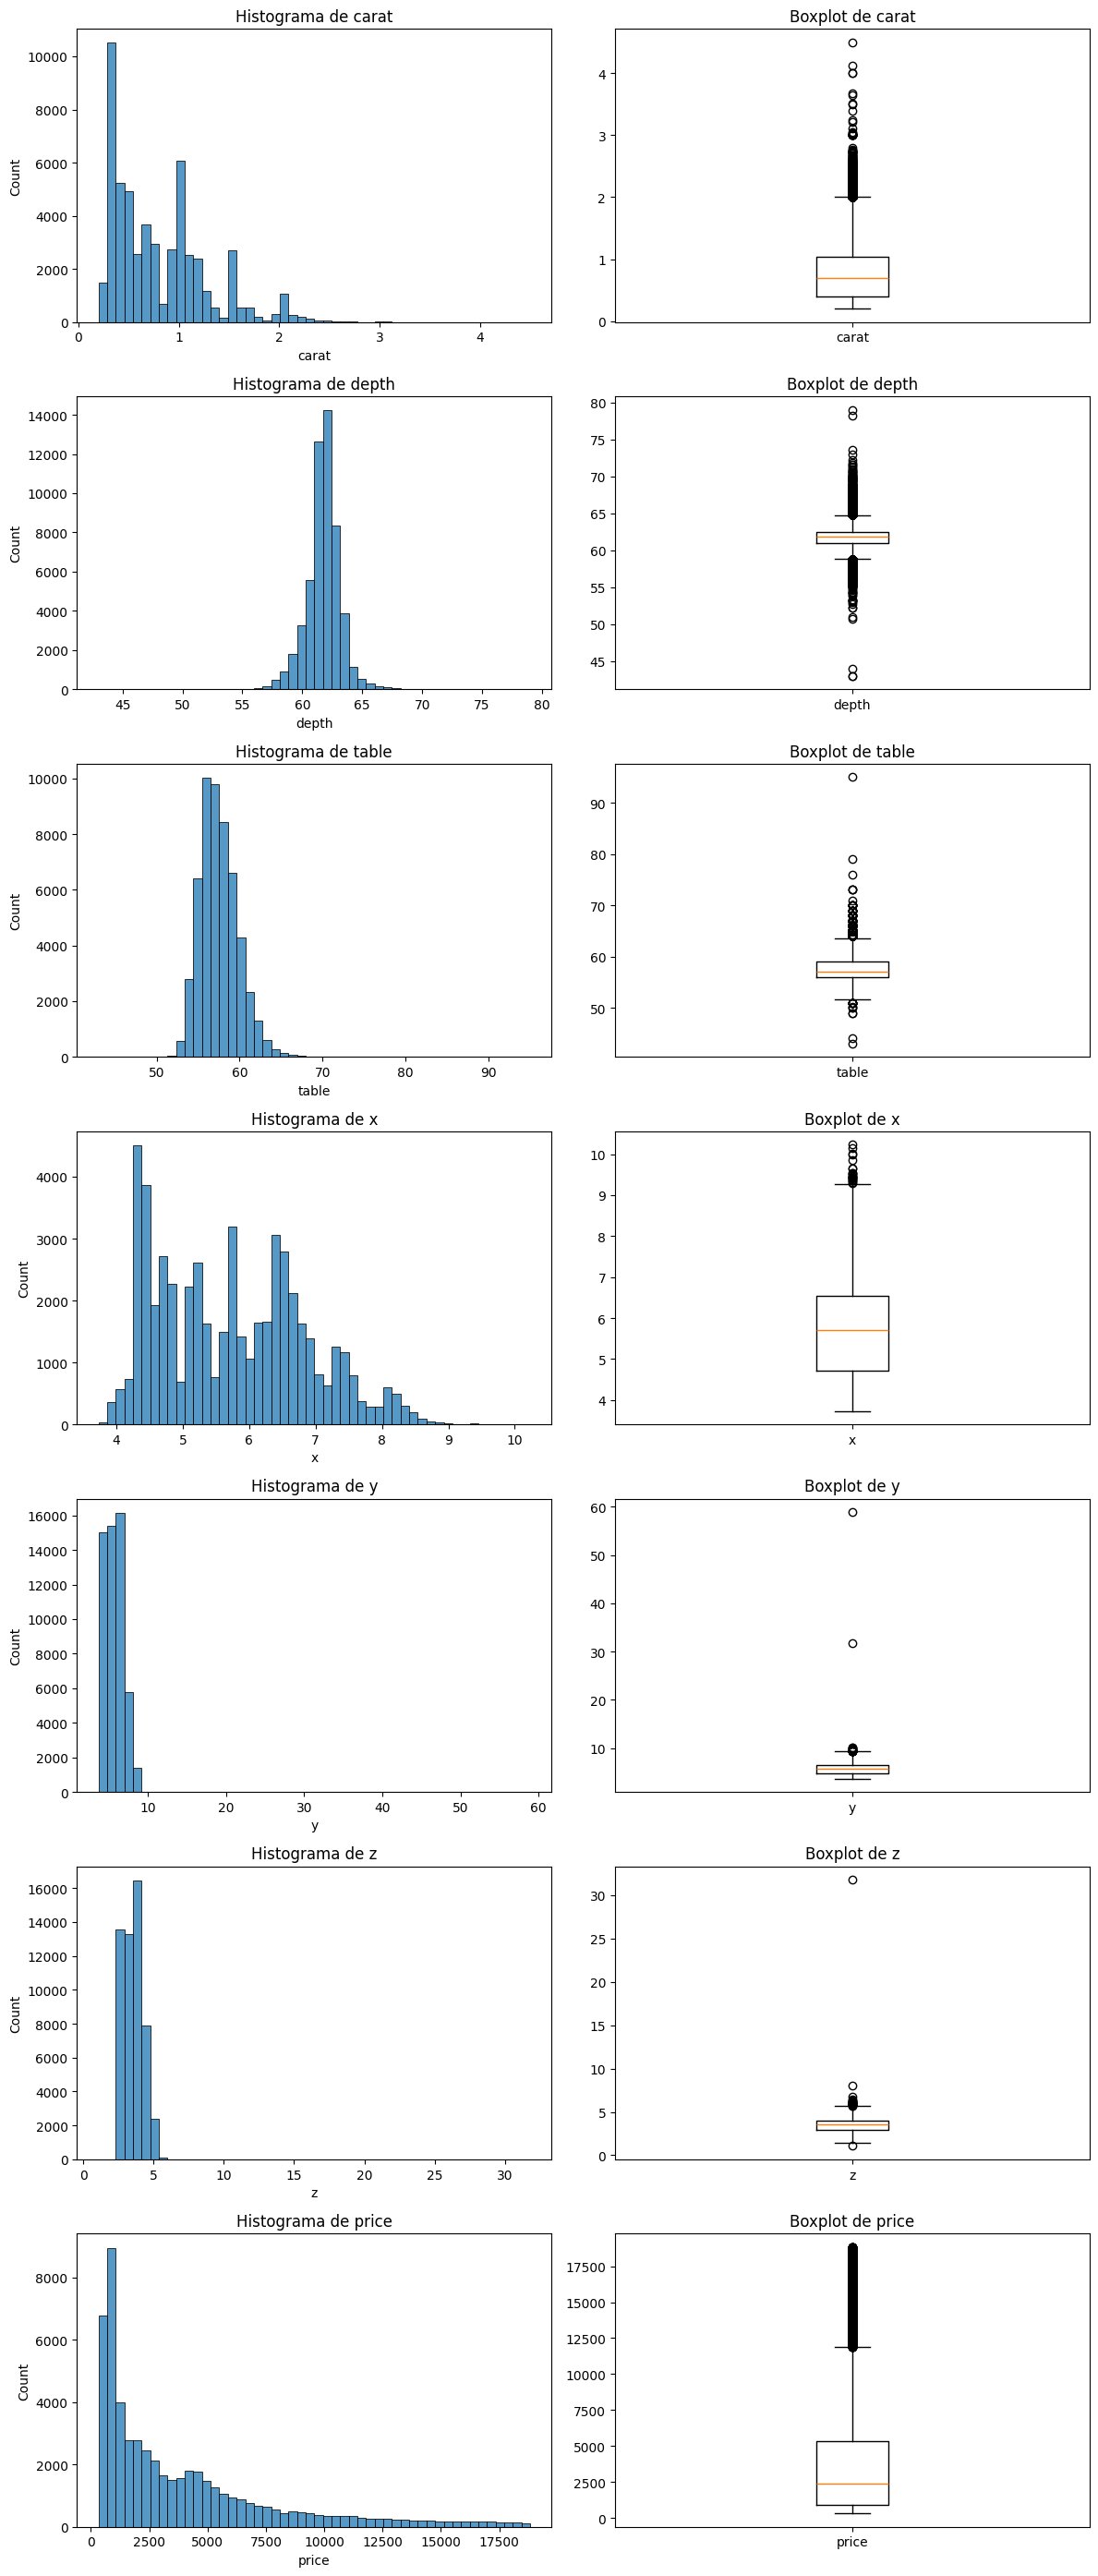

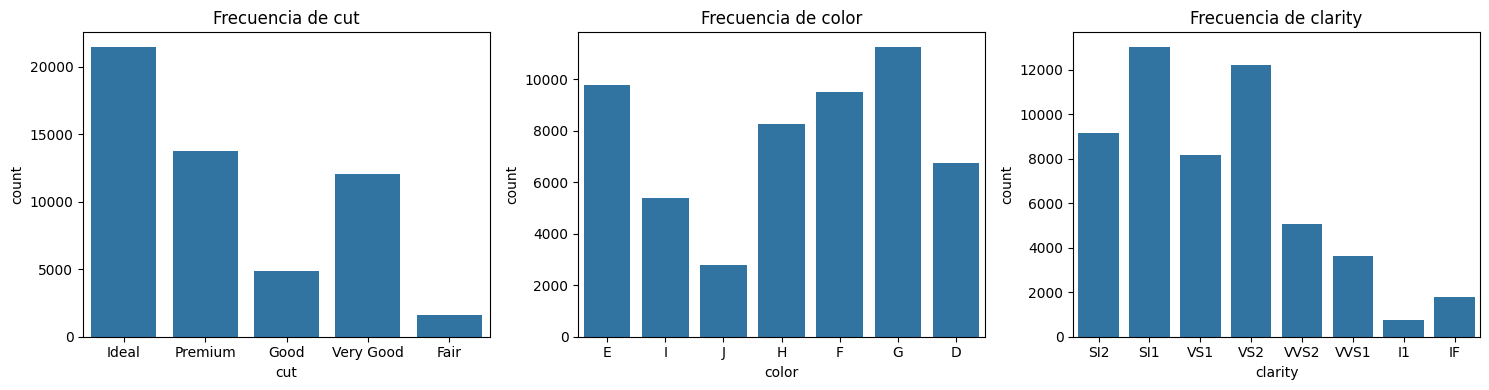

In [3]:
num_cols = diamonds_df.select_dtypes(include='number').columns
cat_cols = diamonds_df.select_dtypes(exclude='number').columns

# Estadísticas descriptivas
display(diamonds_df[num_cols].describe().T)
display(diamonds_df[cat_cols].describe().T)

# Tablas de frecuencia de las categóricas
for col in cat_cols:
    display(diamonds_df[col].value_counts().to_frame())

# Histogramas y boxplots de las numéricas
fig, axes = plt.subplots(len(num_cols), 2, figsize=(12, 4 * len(num_cols)))
for i, col in enumerate(num_cols):
    sns.histplot(diamonds_df[col], bins=50, ax=axes[i, 0])
    axes[i, 0].set_title(f'Histograma de {col}')
    axes[i, 1].boxplot(diamonds_df[col])
    axes[i, 1].set_xticks([1], [col])
    axes[i, 1].set_title(f'Boxplot de {col}')
plt.tight_layout()
plt.show()

# Diagramas de barras de las categóricas
fig, axes = plt.subplots(1, len(cat_cols), figsize=(15, 4))
for i, col in enumerate(cat_cols):
    sns.countplot(x=diamonds_df[col], ax=axes[i])
    axes[i].set_title(f'Frecuencia de {col}')
plt.tight_layout()
plt.show()

Respuesta 2

Casi todos los diamantes son baratos y chicos. El precio promedio es de 3,930 dólares, pero la mitad cuesta menos de 2,401; unos pocos muy caros, de hasta 18,823, suben el promedio. Con el peso pasa igual: la mayoría pesa menos de un quilate.

Depth y table casi no cambian de un diamante a otro. En y y z hay algunos valores enormes que parecen errores de captura.

En el corte gana Ideal por mucho y Fair es el menos común. En color el más común es G y el menos J. En claridad casi todos están en el medio, SI1 y VS2.

3. Explora relaciones bivariadas en el conjunto de datos mediante gráficos:
* Boxplots que muestren la distribución del precio para cada categoría de color, asegurándose de que las categorías se muestren en el orden de calidad de diamante de mejor a peor: D, E, F, G, H, I, J.
* ¿La tendencia de los precios se comporta como esperabas? Identifica si alguna otra variable podría estar influyendo en la tendencia observada por color y comenta tus observaciones.
* Gráfico de dispersión del precio frente al peso de los diamantes, coloreando los puntos según la categoría de calidad del corte.
* ¿Qué relación se observa entre el peso del diamante y su precio según la calidad del corte?

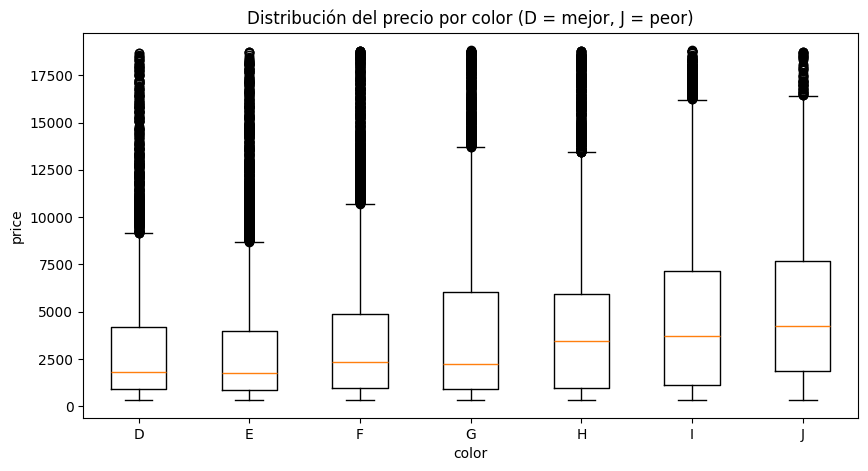

,price,carat
color,,
D,1842.0,0.53
E,1741.5,0.53
F,2345.0,0.70
G,2242.0,0.70
H,3447.0,0.90
I,3719.0,1.00
J,4234.0,1.11


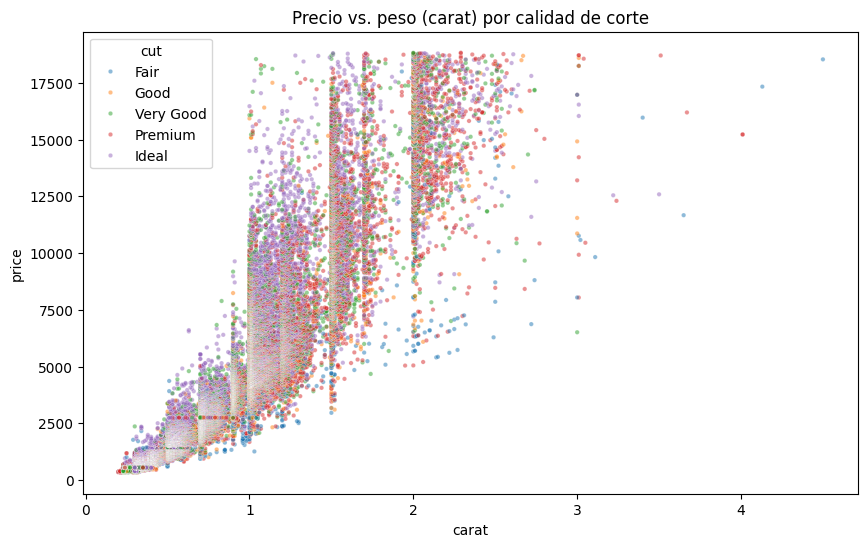

In [4]:
orden_color = ['D', 'E', 'F', 'G', 'H', 'I', 'J']

plt.figure(figsize=(10, 5))
plt.boxplot([diamonds_df.loc[diamonds_df['color'] == c, 'price'] for c in orden_color])
plt.xticks(range(1, len(orden_color) + 1), orden_color)
plt.xlabel('color')
plt.ylabel('price')
plt.title('Distribución del precio por color (D = mejor, J = peor)')
plt.show()

display(diamonds_df.groupby('color')[['price', 'carat']].median().loc[orden_color])

plt.figure(figsize=(10, 6))
sns.scatterplot(data=diamonds_df, x='carat', y='price', hue='cut',
                hue_order=['Fair', 'Good', 'Very Good', 'Premium', 'Ideal'], alpha=0.5, s=10)
plt.title('Precio vs. peso (carat) por calidad de corte')
plt.show()

Respuesta 3

Esperaba que los diamantes de mejor color (D) fueran los más caros, pero pasa al revés: los J, que son los de peor color, salen más caros. La mitad de los J cuesta más de 4,234 dólares y la mitad de los D menos de 1,842.

La explicación está en el tamaño. La mediana de peso de los J es de 1.11 quilates y la de los D de 0.53, o sea el doble, y el peso cuenta más que el color.

En la gráfica de dispersión se ve claro: entre más pesa el diamante, más cuesta, sin importar el corte, y el precio sube cada vez más rápido, no en línea recta. A igual peso, los de mejor corte suelen costar un poco más; los Fair quedan casi siempre en la parte de abajo de la nube.

4. Dibuja un mapa de calor con la matriz de correlación para las variables numéricas del conjunto de datos.
* Identifica los pares de variables cuya correlación sea superior a 0.9 e imprímelos.
* Analiza la correlación entre los predictores (excluyendo `price`), identifica si un único predictor captura información que también está presente en varios otros y elimina los predictores redundantes para simplificar la complejidad de los modelos que construirás más adelante.
* Vuelve a generar el mapa de calor para verificar que ya no queden predictores altamente correlacionados.

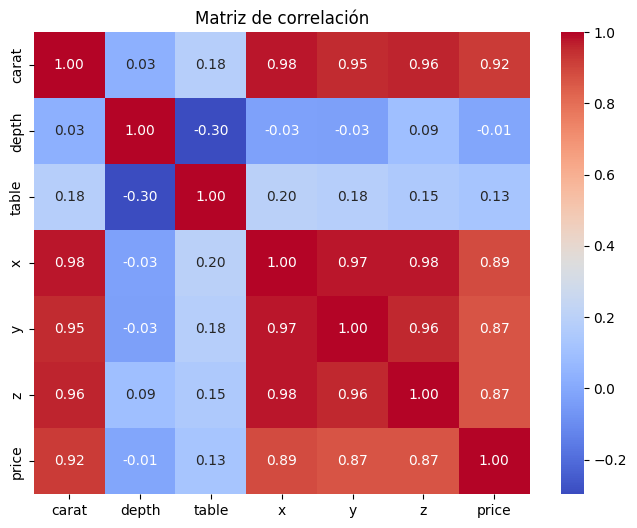

carat - x 0.978
carat - y 0.954
carat - z 0.961
carat - price 0.922
x - y 0.975
x - z 0.975
y - z 0.957


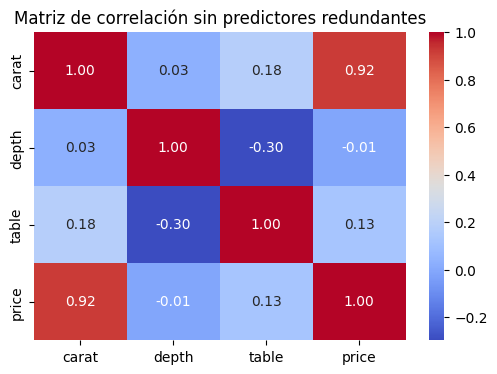

In [5]:
corr = diamonds_df[num_cols].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Matriz de correlación')
plt.show()

# Pares con correlación mayor a 0.9
for i in range(len(corr.columns)):
    for j in range(i + 1, len(corr.columns)):
        if abs(corr.iloc[i, j]) > 0.9:
            print(corr.columns[i], '-', corr.columns[j], round(corr.iloc[i, j], 3))

# carat ya trae la información de x, y, z: se eliminan
diamonds_df = diamonds_df.drop(columns=['x', 'y', 'z'])
num_cols = diamonds_df.select_dtypes(include='number').columns

plt.figure(figsize=(6, 4))
sns.heatmap(diamonds_df[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Matriz de correlación sin predictores redundantes')
plt.show()

Respuesta 4

Salieron 7 pares con correlación arriba de 0.9. Seis son entre carat, x, y y z, y el otro es carat con price. Lo de las medidas tiene lógica: si un diamante es más largo, ancho y alto, también pesa más.

Como carat ya dice lo mismo que las tres medidas, se quitaron x, y y z. En el nuevo mapa ya no queda ningún par muy relacionado. Carat sigue siendo la variable más ligada al precio (0.92).

5. Construye un modelo de regresión simple utilizando únicamente la variable predictora que tenga la mayor correlación con `price`. Para ello:
* Asigna esta variable a `X` y `price` a `y` y divide el conjunto de datos en entrenamiento y prueba (80:20), usando `random_state=1` para garantizar reproducibilidad.
* Entrena un modelo con `LinearRegression()` de scikit-learn y evalúalo en el conjunto de prueba utilizando las métricas `RMSE` (Root Mean Squared Error) y `R²` (coeficiente de determinación).
* Añade los valores obtenidos a un dataframe de resultados, que incluya el nombre del modelo (*Baseline*) y una columna para cada métrica.
* Muestra la ecuación de la regresión lineal utilizando el intercepto y el coeficiente asociado al predictor. La ecuación debe tener la forma:
> `price = intercepto + coeficiente × predictor`

In [6]:
X = diamonds_df[['carat']]
y = diamonds_df['price']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

modelo = LinearRegression()
modelo.fit(X_train, y_train)
y_pred = modelo.predict(X_test)

rmse = root_mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

resultados = pd.DataFrame([{'Modelo': 'Baseline', 'RMSE': rmse, 'R2': r2}])
display(resultados)

print(f'price = {modelo.intercept_:.2f} + {modelo.coef_[0]:.2f} x carat')

,Modelo,RMSE,R2
0,Baseline,1532.43849,0.84618


price = -2276.79 + 7792.73 x carat


Respuesta 5

Se usó carat porque es la que más se relaciona con el precio. Solo con el peso, el modelo explica el 84.6 % del precio (R2 = 0.846) y su error típico (RMSE) es de unos 1,532 dólares.

La ecuación quedó así: price = -2276.79 + 7792.73 x carat

En palabras simples, cada quilate extra sube el precio unos 7,793 dólares. El número negativo del inicio no significa nada en la vida real, porque no hay diamantes de 0 quilates.

6. Utiliza todas las variables como predictoras para crear un segundo modelo:
* Haz la asignación correspondiente en `X` y `y` y divide en entrenamiento y prueba usando la misma configuración del ejercicio anterior.
* Prepara un transformador, denominado `preprocessing`, para aplicar escalamiento robusto a los predictores numéricos y codificación ordinal a los categóricos. Asegúrate de respetar el orden correcto de cada categoría, tal como se indica en la descripción de las variables.
* Construye un pipeline que combine el transformador creado con un modelo de regresión lineal.
* Añade los valores de las métricas obtenidas al dataframe de resultados, utilizando como nombre del modelo *Ordinal_Robust*.

In [7]:
X = diamonds_df.drop(columns='price')
y = diamonds_df['price']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

orden_cut = ['Fair', 'Good', 'Very Good', 'Premium', 'Ideal']
orden_color = ['J', 'I', 'H', 'G', 'F', 'E', 'D']
orden_clarity = ['I1', 'SI2', 'SI1', 'VS2', 'VS1', 'VVS2', 'VVS1', 'IF']

preprocessing = ColumnTransformer([
    ('num', RobustScaler(), ['carat', 'depth', 'table']),
    ('cat', OrdinalEncoder(categories=[orden_cut, orden_color, orden_clarity]), ['cut', 'color', 'clarity'])
])

pipeline1 = make_pipeline(preprocessing, LinearRegression())
pipeline1.fit(X_train, y_train)
y_pred = pipeline1.predict(X_test)

resultados = pd.concat([resultados, pd.DataFrame([{
    'Modelo': 'Ordinal_Robust',
    'RMSE': root_mean_squared_error(y_test, y_pred),
    'R2': r2_score(y_test, y_pred)}])], ignore_index=True)
display(resultados)

,Modelo,RMSE,R2
0,Baseline,1532.438490,0.846180
1,Ordinal_Robust,1216.822219,0.903016


Respuesta 6

Al meter todas las variables el modelo mejora: el R2 sube de 0.846 a 0.903 y el error baja de 1,532 a 1,217 dólares.

O sea, el peso no lo es todo; el corte, el color y la claridad también cuentan. Las categorías se pasaron a números de peor a mejor para que el modelo entendiera su orden.

7. Prepara otro transformador, llamado `preprocessing2`, que aplique escalamiento Min-Max a los predictores numéricos y codificación one-hot a los categóricos, asegurando `drop='first'` para prevenir multicolinealidad en las variables dummies generadas.
* Construye otro pipeline utilizando este nuevo transformador y, a continuación, entrena y evalúa el modelo.
* Añade los valores de las métricas obtenidas al dataframe de resultados, utilizando como nombre del modelo *OHE_MinMax*.

In [8]:
preprocessing2 = ColumnTransformer([
    ('num', MinMaxScaler(), ['carat', 'depth', 'table']),
    ('cat', OneHotEncoder(drop='first'), ['cut', 'color', 'clarity'])
])

pipeline2 = make_pipeline(preprocessing2, LinearRegression())
pipeline2.fit(X_train, y_train)
y_pred = pipeline2.predict(X_test)

resultados = pd.concat([resultados, pd.DataFrame([{
    'Modelo': 'OHE_MinMax',
    'RMSE': root_mean_squared_error(y_test, y_pred),
    'R2': r2_score(y_test, y_pred)}])], ignore_index=True)
display(resultados)

,Modelo,RMSE,R2
0,Baseline,1532.438490,0.846180
1,Ordinal_Robust,1216.822219,0.903016
2,OHE_MinMax,1142.519131,0.914499


Respuesta 7

Con este cambio el modelo mejora otro poco: R2 de 0.914 y error de 1,143 dólares.

La razón es que ahora cada categoría tiene su propio peso en el precio. Antes el modelo suponía que subir de un nivel a otro valía siempre lo mismo, y en la realidad no es así.

8. Modifica el pipeline anterior para emplear regresión polinomial de segundo grado y evalúa si esto mejora el ajuste del modelo.
* Añade los valores de las métricas obtenidas al dataframe de resultados, utilizando como nombre del modelo *PolynomialDegree2*.

In [9]:
pipeline3 = make_pipeline(preprocessing2, PolynomialFeatures(degree=2), LinearRegression())
pipeline3.fit(X_train, y_train)
y_pred = pipeline3.predict(X_test)

resultados = pd.concat([resultados, pd.DataFrame([{
    'Modelo': 'PolynomialDegree2',
    'RMSE': root_mean_squared_error(y_test, y_pred),
    'R2': r2_score(y_test, y_pred)}])], ignore_index=True)
display(resultados)

,Modelo,RMSE,R2
0,Baseline,1532.438490,0.846180
1,Ordinal_Robust,1216.822219,0.903016
2,OHE_MinMax,1142.519131,0.914499
3,PolynomialDegree2,749.022631,0.963252


Respuesta 8

Aquí está la mejora más grande. Con la regresión polinomial el R2 llega a 0.963 y el error baja a 749 dólares, menos de la mitad que con el modelo simple (1,532).

Tiene sentido: el precio no sube parejo con el peso. Un diamante de 2 quilates vale mucho más que dos de 1, y una curva captura eso mejor que una línea recta.

9. Ordena el dataframe de resultados según el `R²`, de manera que el modelo con mejor desempeño aparezca primero.
* Para dicho modelo, crea un gráfico de dispersión de los valores reales frente a los predichos, e incluye una línea diagonal de referencia para indicar una predicción perfecta.

,Modelo,RMSE,R2
0,PolynomialDegree2,749.022631,0.963252
1,OHE_MinMax,1142.519131,0.914499
2,Ordinal_Robust,1216.822219,0.903016
3,Baseline,1532.438490,0.846180


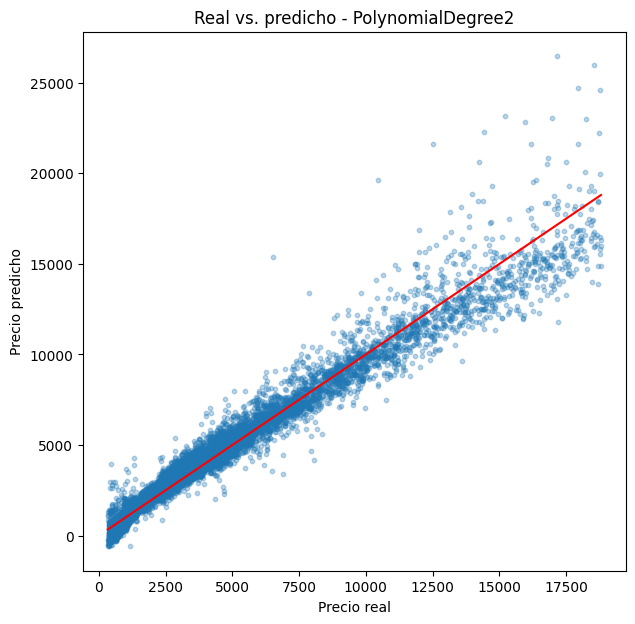

In [10]:
resultados = resultados.sort_values('R2', ascending=False).reset_index(drop=True)
display(resultados)

y_pred_mejor = pipeline3.predict(X_test)

plt.figure(figsize=(7, 7))
plt.scatter(y_test, y_pred_mejor, alpha=0.3, s=10)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red')
plt.xlabel('Precio real')
plt.ylabel('Precio predicho')
plt.title('Real vs. predicho - PolynomialDegree2')
plt.show()

Respuesta 9

El mejor modelo fue el polinomial, seguido de OHE_MinMax, Ordinal_Robust y al final el simple.

En la gráfica casi todos los puntos quedan pegados a la línea roja, así que el modelo le atina bien. Donde más falla es con los diamantes caros, de más de 10,000 dólares: ahí los puntos se abren, a la mayoría les predice menos de lo que valen y a unos pocos mucho más, hasta cerca de 26,000. En los más baratos llega a dar precios negativos, algo que no puede pasar en la realidad.

10. Muestra la representación gráfica del pipeline para ubicar la posición de cada elemento dentro del flujo del modelo.
* Obtén los nombres de todas las columnas después del preprocesamiento (numéricas y dummies de categóricas).
* Extrae los nombres de las columnas polinómicas.
* Recupera los coeficientes y el intercepto del modelo de regresión lineal.
* Ordena los coeficientes por su valor absoluto para mostrar los 10 más importantes y da conclusiones sobre cómo los distintos factores influyen en el precio.

In [11]:
from sklearn import set_config
set_config(display='diagram')
display(pipeline3)

nombres = pipeline3.named_steps['columntransformer'].get_feature_names_out()
print('Columnas después del preprocesamiento:')
print(list(nombres))

nombres_poly = pipeline3.named_steps['polynomialfeatures'].get_feature_names_out(nombres)
print('Total de columnas polinómicas:', len(nombres_poly))
print('Primeras 30:', list(nombres_poly[:30]))

modelo_lr = pipeline3.named_steps['linearregression']
print('Intercepto:', round(modelo_lr.intercept_, 2))

coeficientes = pd.DataFrame({'Variable': nombres_poly, 'Coeficiente': modelo_lr.coef_})
coeficientes['Abs'] = coeficientes['Coeficiente'].abs()
display(coeficientes.sort_values('Abs', ascending=False).head(10)[['Variable', 'Coeficiente']])

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('num', MinMaxScaler(),
                                                  ['carat', 'depth', 'table']),
                                                 ('cat',
                                                  OneHotEncoder(drop='first'),
                                                  ['cut', 'color',
                                                   'clarity'])])),
                ('polynomialfeatures', PolynomialFeatures()),
                ('linearregression', LinearRegression())])

Columnas después del preprocesamiento:
['num__carat', 'num__depth', 'num__table', 'cat__cut_Good', 'cat__cut_Ideal', 'cat__cut_Premium', 'cat__cut_Very Good', 'cat__color_E', 'cat__color_F', 'cat__color_G', 'cat__color_H', 'cat__color_I', 'cat__color_J', 'cat__clarity_IF', 'cat__clarity_SI1', 'cat__clarity_SI2', 'cat__clarity_VS1', 'cat__clarity_VS2', 'cat__clarity_VVS1', 'cat__clarity_VVS2']
Total de columnas polinómicas: 231
Primeras 30: ['1', 'num__carat', 'num__depth', 'num__table', 'cat__cut_Good', 'cat__cut_Ideal', 'cat__cut_Premium', 'cat__cut_Very Good', 'cat__color_E', 'cat__color_F', 'cat__color_G', 'cat__color_H', 'cat__color_I', 'cat__color_J', 'cat__clarity_IF', 'cat__clarity_SI1', 'cat__clarity_SI2', 'cat__clarity_VS1', 'cat__clarity_VS2', 'cat__clarity_VVS1', 'cat__clarity_VVS2', 'num__carat^2', 'num__carat num__depth', 'num__carat num__table', 'num__carat cat__cut_Good', 'num__carat cat__cut_Ideal', 'num__carat cat__cut_Premium', 'num__carat cat__cut_Very Good', 'num__c

,Variable,Coeficiente
21,num__carat^2,55138.730096
34,num__carat cat__clarity_IF,49902.343150
39,num__carat cat__clarity_VVS1,46676.320763
40,num__carat cat__clarity_VVS2,44778.211304
37,num__carat cat__clarity_VS1,40030.062557
38,num__carat cat__clarity_VS2,37092.384913
35,num__carat cat__clarity_SI1,31996.932521
36,num__carat cat__clarity_SI2,24370.431812
33,num__carat cat__color_J,-20648.235154
32,num__carat cat__color_I,-14267.857129


Respuesta 10

El pipeline tiene tres pasos: primero prepara los datos (Min-Max para los números y one-hot para las categorías), luego crea las columnas polinomiales y al final hace la regresión. Después de preparar los datos quedan 20 columnas, que con el polinomio se vuelven 231. El intercepto sale cerca de -900.

Lo que más pesa en el precio es el peso al cuadrado. Quiere decir que el precio sube cada vez más rápido entre más grande es el diamante.

Después viene la claridad combinada con el peso. El peso vale mucho más en un diamante muy limpio (IF, VVS1, VVS2) que en uno con claridad baja: el coeficiente de peso con IF es el doble que el de peso con SI2.

El color funciona al revés: en los diamantes grandes, un mal color (J o I) le baja bastante el precio frente a uno D.

En resumen, primero manda el tamaño, y luego la claridad y el color deciden cuánto vale cada quilate. El corte casi no aparece entre lo más importante.

Hay que leer estos coeficientes con cuidado: están en la escala de 0 a 1 de Min-Max y cada categoría se compara contra la que quitó drop='first' (corte Fair, color D y claridad I1), así que sirven para ver qué pesa más, no para leerlos como dólares por quilate.

---

**Declaración de uso de IA**

Anthropic. (2026). Claude (Opus 5.5) [Modelo de lenguaje grande], utilizado para depuración de código, y como apoyo en la redaccion correcta de las respuestas. https://claude.ai/